# A Yarkovsky survey: thermal drift across near-Earth asteroids

**The question.** A small asteroid absorbs sunlight and re-emits it as heat a few hours later,
after its rotation has carried the warm surface around. The thermal photons leave with a
slight preference for one direction along the orbit, and the recoil, the **Yarkovsky effect**,
slowly changes the orbit's size. A prograde rotator spirals outward, a retrograde one inward.
The push is tiny (about $10^{-14}$ au/day², a few billionths of the Sun's pull at 1 au), but
decades of astrometry make it measurable, and JPL now publishes it for hundreds of near-Earth
asteroids (Farnocchia et al. 2013, *Icarus* 224, 1; Greenberg et al. 2020, *AJ* 159, 92).

The drift is a surface force acting on a mass, so it scales as area over mass: for a given
density and spin, $da/dt \propto 1/D$. A measured drift therefore says something about the
body itself: with its size and spin axis known, about its **bulk density**.

PyRoOrb models the effect the way JPL does: a transverse acceleration $A_2\,(1\,\mathrm{au}/r)^2$
along the direction of motion. With `nongrav="auto"`, every fit of an asteroid with perihelion
inside 1.4 au and two or more apparitions also tries $A_2$ (and a radial $A_1$) and keeps a
model only when it earns its extra parameter by a wide information-criterion margin
(ΔBIC ≥ 15). With `nongrav="yarkovsky"` it fits $A_2$ whether or not it is earned.

This notebook runs both on a sample of near-Earth asteroids and asks:

1. **Does the automatic fit find the drift JPL finds, and only there?** Twelve objects with a
   JPL-published $A_2$, from 0.2 to 1.4 km across, and three well-observed controls that JPL fits with
   gravity alone.
2. **Do the values agree?** PyRoOrb's $A_2$ against JPL's, object by object, in units of the
   combined uncertainty.
3. **What does it mean physically?** $A_2$ converted to a drift rate $da/dt$, plotted against
   size with the expected $1/D$ trend; and, for Ryugu and Itokawa, the bulk density implied by
   their drift when Bennu (density measured in situ by OSIRIS-REx) is used as the yardstick,
   compared with the densities the Hayabusa missions measured.

Runtime: about 15 minutes on a laptop (some twenty-five orbit fits from the full observation
records, many with radar). It needs the asteroid perturber kernel (`pyroorb-fetch-data --asteroids`).

In [1]:
import json, time, urllib.parse, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.1


JPL fits these orbits with the 16 most massive asteroids as perturbers (its `SB441-N16` kernel).
A Yarkovsky drift is a few hundred metres per year in semi-major axis, small enough that a
missing perturber could imitate part of it, so we do the same.

In [2]:
pyroorb.asteroid_perturbers()        # the 16 most massive asteroids perturb every fit below

asteroid perturbers on (sb441-n16.bsp)

## 1. The sample, and what JPL says about it

JPL's Small-Body Database returns, for each object, the non-gravitational parameters of its
current orbit solution (`model_pars`; $A_2$ with its 1σ when one was fitted) and the physical
parameters (diameter, albedo, $H$). Where no measured diameter is listed we use
$D = 1329\,\mathrm{km}/\sqrt{p_V}\;10^{-H/5}$ with the NEA-typical albedo $p_V = 0.14$.

The sample was chosen for a spread of sizes and orbits, a JPL $A_2$ detected at 4σ or better,
and a fit that takes at most a few minutes. Three objects one might expect here are left out
for runtime: (99942) Apophis (9,500 observations; its $A_2$ is checked in notebook 02) and
(3200) Phaethon (8,000); and (1566) Icarus, (2340) Hathor and (152563) 1992 BF, whose fits
took 15-25 minutes or more each on the machine used here (long arcs reaching back to old
photographic positions, which make the automatic fit work much harder than the observation
count suggests). The controls are
near-Earth asteroids with 30-70 years of observations and no JPL $A_2$; their diameters
(1.8-3.4 km) make a detectable drift less likely, though not impossible.

In [3]:
def jpl(api, **params):
    """Query one of JPL's SSD APIs (sbdb, ...) and return the JSON."""
    url = f"https://ssd-api.jpl.nasa.gov/{api}.api?" + urllib.parse.urlencode(params)
    with urllib.request.urlopen(url, timeout=60) as r:
        return json.load(r)

SAMPLE = ["101955", "162173", "25143", "4769", "2062", "2063", "85990", "3908",
          "138175", "3361", "480883", "6489"]
CONTROLS = ["5011", "4197", "1981"]

rows = []
for des in SAMPLE + CONTROLS:
    s = jpl("sbdb", sstr=des, **{"full-prec": 1, "phys-par": 1})
    orb, phys = s["orbit"], {p["name"]: p["value"] for p in s.get("phys_par", [])}
    mp = {p["name"]: p for p in orb.get("model_pars", [])}
    el = {e["name"]: float(e["value"]) for e in orb["elements"]}
    H = float(phys["H"])
    D_meas = phys.get("diameter")
    rows.append({
        "des": des, "name": s["object"]["fullname"].strip(),
        "control": des in CONTROLS,
        "a": el["a"], "e": el["e"], "q": el["q"],
        "D_km": float(D_meas) if D_meas else 1329 / np.sqrt(0.14) * 10 ** (-H / 5),
        "D_source": "SBDB" if D_meas else "H, pV=0.14",
        "jpl_A2": float(mp["A2"]["value"]) if "A2" in mp else np.nan,
        "jpl_sA2": float(mp["A2"]["sigma"]) if "A2" in mp else np.nan,
        "jpl_model": "+".join(k for k in ("A1", "A2", "A3", "AMRAT", "RHO") if k in mp) or "gravity",
        "jpl_nobs": orb["n_obs_used"], "jpl_arc_yr": float(orb["data_arc"]) / 365.25,
    })
sample = pd.DataFrame(rows).set_index("des")

def short(des):
    """'Bennu' for a named object, '(1999 JV6)' for an unnamed one."""
    rest = sample.loc[des, "name"].split(" ", 1)[1]
    return rest if rest.startswith("(") else rest.split(" (")[0]
show = sample[["name", "q", "D_km", "D_source", "jpl_model", "jpl_A2", "jpl_sA2", "jpl_nobs", "jpl_arc_yr"]]
show.style.format({"q": "{:.2f}", "D_km": "{:.2f}", "jpl_A2": "{:.3e}", "jpl_sA2": "{:.1e}",
                   "jpl_arc_yr": "{:.0f}"}, na_rep="-")

,name,q,D_km,D_source,jpl_model,jpl_A2,jpl_sA2,jpl_nobs,jpl_arc_yr
des,,,,,,,,,
101955,101955 Bennu (1999 RQ36),0.90,0.48,SBDB,AMRAT+RHO,-,-,554,21
162173,162173 Ryugu (1999 JU3),0.96,0.90,SBDB,A2,-2.487e-14,5.0e-15,5124,39
25143,25143 Itokawa (1998 SF36),0.95,0.33,SBDB,A2,-2.855e-14,7.2e-15,1025,26
4769,4769 Castalia (1989 PB),0.55,1.40,SBDB,A2,-8.628e-15,9.8e-16,746,37
2062,2062 Aten (1976 AA),0.79,1.10,SBDB,A2,-1.061e-14,1.1e-15,1024,64
2063,2063 Bacchus (1977 HB),0.70,1.02,SBDB,A2,-8.147e-15,7.9e-16,1561,48
85990,85990 (1999 JV6),0.69,0.45,SBDB,A2,-3.564e-14,2.7e-15,1203,25
3908,3908 Nyx (1980 PA),1.04,1.00,SBDB,A2,1.106e-14,2.3e-15,1985,45
138175,138175 (2000 EE104),0.71,0.28,"H, pV=0.14",A2,-8.595e-14,4.3e-15,1621,26


One entry stands out: **(101955) Bennu has no $A_2$ at JPL any more.** After OSIRIS-REx mapped
its shape, spin and surface, JPL replaced the empirical $A_2$ with a full thermal model of the
real body, whose free parameters are a density (`RHO`) and a radiation-pressure area-to-mass
ratio (`AMRAT`). For Bennu we compare with the last published $A_2$ fit instead:
$A_2 = (-4.618 \pm 0.024)\times10^{-14}$ au/day², $da/dt = (-19.0 \pm 0.1)\times10^{-4}$ au/Myr
(Chesley et al. 2014, *Icarus* 235, 5), from the optical and radar astrometry available
before the spacecraft arrived.

In [4]:
BENNU_A2_CHESLEY14 = (-4.618e-14, 0.024e-14)          # au/day^2, Chesley et al. 2014
sample.loc["101955", ["jpl_A2", "jpl_sA2"]] = BENNU_A2_CHESLEY14
sample.loc["101955", "jpl_model"] = "A2 (Chesley+2014)"

## 2. The automatic fits

Each object: fetch every observation the MPC has (radar delay and Doppler come along when
they exist), fit with `nongrav="auto"`, and time it.

In [5]:
fits, timing, n_radar = {}, {}, {}
for des in SAMPLE + CONTROLS:
    t0 = time.time()
    obs = pyroorb.fetch_observations(des)
    fits[des] = pyroorb.fit_orbit(obs, designation=des)          # nongrav="auto"
    timing[des] = time.time() - t0
    n_radar[des] = len(obs.meta.get("radar") or [])
    f = fits[des]
    a2 = f.nongrav_params.get("A2")
    print(f"{sample.loc[des, 'name']:28s} {f.n_observations():5d}/{len(obs):5d} obs "
          f"{n_radar[des]:3d} radar  rms {f.rms_residual():.3f}\"  "
          f"model: {f.nongrav_model or 'gravity':10s}"
          + (f"A2 = {a2:+.3e}" if a2 is not None else " " * 17)
          + f"  {timing[des]:5.0f} s")
print(f"\ntotal {sum(timing.values()) / 60:.1f} min")

101955 Bennu (1999 RQ36)       592/  603 obs  29 radar  rms 0.432"  model: yarkovsky A2 = -4.466e-14     23 s


162173 Ryugu (1999 JU3)       4829/ 5037 obs   2 radar  rms 1.123"  model: yarkovsky A2 = -2.472e-14     50 s


25143 Itokawa (1998 SF36)     1246/ 1260 obs  39 radar  rms 0.481"  model: gravity                          9 s


4769 Castalia (1989 PB)        739/  746 obs  14 radar  rms 0.658"  model: yarkovsky A2 = -7.857e-15    102 s


2062 Aten (1976 AA)           1048/ 1054 obs   7 radar  rms 0.645"  model: yarkovsky A2 = -1.607e-14     70 s


2063 Bacchus (1977 HB)        1480/ 1532 obs  12 radar  rms 0.582"  model: gravity                         27 s


... (5 outputs left out)

6489 Golevka (1991 JX)         937/  980 obs  40 radar  rms 0.734"  model: gravity                         11 s


5011 Ptah (6743 P-L)           779/  784 obs   0 radar  rms 0.536"  model: gravity                         13 s


4197 Morpheus (1982 TA)       1254/ 1290 obs   6 radar  rms 0.678"  model: gravity                         36 s


1981 Midas (1973 EA)          2370/ 2402 obs   7 radar  rms 0.498"  model: gravity                         34 s

total 11.2 min


## 3. Detection: who fired, and who did not

In [6]:
sample["auto_model"] = [fits[d].nongrav_model or "gravity" for d in sample.index]
sample["fired"] = sample["auto_model"] != "gravity"
det = sample[~sample.control]
print(f"JPL detections recovered automatically: {det.fired.sum()} of {len(det)}")
print(f"controls with a model switched on:      {sample[sample.control].fired.sum()} of {len(CONTROLS)}")
print("\nnot recovered:", ", ".join(det[~det.fired].name))

JPL detections recovered automatically: 7 of 12
controls with a model switched on:      0 of 3

not recovered: 25143 Itokawa (1998 SF36), 2063 Bacchus (1977 HB), 85990 (1999 JV6), 3908 Nyx (1980 PA), 6489 Golevka (1991 JX)


Seven of the twelve JPL detections are found without help, and none of the three controls gets
a model switched on. The five misses have one thing in common: **all five have radar
astrometry** (12 to 40 delay and Doppler measurements each). Not every radar object is missed
(Bennu, Castalia, Aten and 2001 YE4 have radar too and are found), but every miss is a radar
object. The next two cells show why.

### Forcing the model on

`nongrav="yarkovsky"` fits $A_2$ on every object regardless. For the objects the automatic fit
left gravity-only we fit it that way too; the $A_2$ it finds, and how much it lowers the
residuals, show what the automatic decision turned down.

In [7]:
forced = {}
for des in sample.index[~sample.fired]:
    t0 = time.time()
    obs = pyroorb.fetch_observations(des)
    forced[des] = pyroorb.fit_orbit(obs, designation=des, nongrav="yarkovsky")
    timing[des] += time.time() - t0

rows = []
for des, fy in forced.items():
    g = fits[des]
    a2, s2 = fy.nongrav_params["A2"], fy.as_dict()["nongrav_sigmas"]["A2"]
    rows.append({"object": sample.loc[des, "name"], "control": sample.loc[des, "control"],
                 "rms gravity (\")": round(g.rms_residual(), 3),
                 "rms with A2 (\")": round(fy.rms_residual(), 3),
                 "radar": n_radar[des],
                 "forced A2": f"{a2:+.2e} ± {s2:.1e}", "A2/σ": round(a2 / s2, 1),
                 "JPL A2": (f"{sample.loc[des, 'jpl_A2']:+.2e} ± {sample.loc[des, 'jpl_sA2']:.1e}"
                            if np.isfinite(sample.loc[des, "jpl_A2"]) else "none fitted")})
pd.DataFrame(rows).set_index("object")

,control,"rms gravity ("")","rms with A2 ("")",radar,forced A2,A2/σ,JPL A2
object,,,,,,,
25143 Itokawa (1998 SF36),False,0.481,0.481,39,-2.28e-14 ± 4.4e-15,-5.2,-2.86e-14 ± 7.2e-15
2063 Bacchus (1977 HB),False,0.582,0.487,12,-8.30e-15 ± 2.0e-16,-41.0,-8.15e-15 ± 7.9e-16
85990 (1999 JV6),False,0.635,0.522,15,-3.42e-14 ± 1.3e-15,-26.6,-3.56e-14 ± 2.7e-15
3908 Nyx (1980 PA),False,0.561,0.554,16,+8.38e-15 ± 8.6e-16,9.8,+1.11e-14 ± 2.3e-15
6489 Golevka (1991 JX),False,0.734,0.733,40,-8.17e-15 ± 1.3e-15,-6.1,-1.22e-14 ± 1.5e-15
5011 Ptah (6743 P-L),True,0.536,0.537,0,+2.82e-15 ± 1.4e-14,0.2,none fitted
4197 Morpheus (1982 TA),True,0.678,0.673,6,+1.19e-14 ± 2.0e-15,6.0,none fitted
1981 Midas (1973 EA),True,0.498,0.499,7,-9.42e-15 ± 1.8e-15,-5.2,none fitted


The misses come in two kinds.

* **(2063) Bacchus and (85990) 1999 JV6 are clear detections the automatic step turned down.**
  With $A_2$ the optical rms drops by 16-18% (0.582″ → 0.487″ and 0.635″ → 0.522″), and the
  forced $A_2$ lands within 0.5σ of JPL's on both.
* **(25143) Itokawa, (6489) Golevka and (3908) Nyx are quieter.** $A_2$ changes their optical
  rms by 1% or less; their drift is carried mostly by a few radar ranges. The forced values agree
  with JPL to 0.7σ, 2.0σ and 1.1σ. On their own, though, these forced fits are no more convincing
  than the controls' (next point): their credibility comes from JPL's independent solution.

The forced fits on the **controls** are the reason the automatic fit uses an information
criterion rather than the formal significance $A_2/\sigma$. Morpheus and Midas come out at 5-6
"sigma" while their rms does not move at all (0.678″ → 0.673″, 0.498″ → 0.499″). A free $A_2$
always absorbs a little of whatever small systematic errors the astrometry carries, and the
formal σ, computed as if the errors were independent and correctly weighted, does not know
that. §6 shows the two values are also implausibly large for bodies of 1.8 and 3.4 km. Ptah's
forced $A_2$ is simply unconstrained (σ = 1.4×10⁻¹⁴).

### Why the radar objects are missed: the radar disagrees with the gravity orbit

(85990) 1999 JV6 shows what happens. Fit it from the optical positions alone, gravity only, and
ask that orbit to predict its 15 radar measurements (`pyroorb.radar_residuals` evaluates any
orbit against any radar list):

In [8]:
obs = pyroorb.fetch_observations("85990")
radar = obs.meta["radar"]
optical_only = obs.select(radar=False)
g_opt = pyroorb.fit_orbit(optical_only, designation="85990", nongrav="none")
y_opt = pyroorb.fit_orbit(optical_only, designation="85990", nongrav="yarkovsky")

for label, f in (("gravity, optical only", g_opt), ("with A2, optical only", y_opt)):
    z = np.array([r["z"] for r in pyroorb.radar_residuals(f, radar)])
    a2 = f.nongrav_params.get("A2")
    print(f"{label:24s} optical rms {f.rms_residual():.3f}\"   radar |O-C|/sigma: median {np.median(abs(z)):6.1f}, "
          f"max {abs(z).max():6.1f}" + (f"   (A2 = {a2:+.2e})" if a2 is not None else ""))
print(f"{'gravity + radar (auto)':24s} optical rms {fits['85990'].rms_residual():.3f}\"")
print(f"{'A2 + radar (forced)':24s} optical rms {forced['85990'].rms_residual():.3f}\"")

gravity, optical only    optical rms 0.532"   radar |O-C|/sigma: median  186.5, max  669.2
with A2, optical only    optical rms 0.526"   radar |O-C|/sigma: median  144.3, max  479.1   (A2 = -1.50e-14)
gravity + radar (auto)   optical rms 0.635"
A2 + radar (forced)      optical rms 0.522"


This is the whole story of the misses in four lines.

* The gravity-only orbit fitted to the optical positions predicts the radar ranges badly: a
  median of **186σ** off, the worst 669σ.
* Letting $A_2$ free in that optical-only fit hardly helps: it finds $A_2 = -1.5\times10^{-14}$,
  less than half of JPL's value, and still misses the radar by 144σ. From the optical
  positions alone, a drift and a small change of the orbit's other elements look almost the
  same, so the drift is underestimated and the rms barely moves (0.532″ → 0.526″).
* The radar resolves that ambiguity. When the gravity orbit is made to fit the radar as well,
  the optical rms *rises* from 0.53″ to 0.635″: without a drift, the two data sets cannot both
  be fitted. With $A_2$ (the forced fit) both are, and the optical rms falls to 0.522″.

PyRoOrb's automatic decision is taken on the **optical positions only**, before the radar joins
the fit; the radar joins afterwards, in a joint solve, only if a model was switched on. On a
radar object whose optical arc cannot tell the drift apart by itself, the decision is
"gravity", and the radar never gets a say. The rise in optical rms when the radar joins is
a cheap warning sign: on 1999 JV6 it is 19%. Until the engine re-tests
the model with the radar included, **on a radar object, fit `nongrav="yarkovsky"` as well
and compare.**

## 4. Do the values agree with JPL?

For every object we take PyRoOrb's $A_2$ (the automatic fit's when it fired, the forced fit's
otherwise, marked) and compare it with JPL's. The *pull* is the difference divided by the two
uncertainties added in quadrature.

In [9]:
def a2_of(des):
    f = fits[des] if sample.loc[des, "fired"] else forced[des]
    return f.nongrav_params["A2"], f.as_dict()["nongrav_sigmas"]["A2"]

sample["A2"], sample["sA2"] = zip(*[a2_of(d) for d in sample.index])
sample["pull"] = (sample.A2 - sample.jpl_A2) / np.hypot(sample.sA2, sample.jpl_sA2)
sample["ratio"] = sample.A2 / sample.jpl_A2
det = sample[~sample.control]
(det[["name", "auto_model", "A2", "sA2", "jpl_A2", "jpl_sA2", "ratio", "pull"]]
 .style.format({"A2": "{:+.3e}", "sA2": "{:.1e}", "jpl_A2": "{:+.3e}", "jpl_sA2": "{:.1e}",
                "ratio": "{:.2f}", "pull": "{:+.1f}"}))

,name,auto_model,A2,sA2,jpl_A2,jpl_sA2,ratio,pull
des,,,,,,,,
101955,101955 Bennu (1999 RQ36),yarkovsky,-4.466e-14,2.4e-16,-4.618e-14,2.4e-16,0.97,+4.5
162173,162173 Ryugu (1999 JU3),yarkovsky,-2.472e-14,1.8e-15,-2.487e-14,5.0e-15,0.99,+0.0
25143,25143 Itokawa (1998 SF36),gravity,-2.285e-14,4.4e-15,-2.855e-14,7.2e-15,0.80,+0.7
4769,4769 Castalia (1989 PB),yarkovsky,-7.857e-15,3.7e-16,-8.628e-15,9.8e-16,0.91,+0.7
2062,2062 Aten (1976 AA),yarkovsky,-1.607e-14,9.9e-16,-1.061e-14,1.1e-15,1.51,-3.6
2063,2063 Bacchus (1977 HB),gravity,-8.302e-15,2.0e-16,-8.147e-15,7.9e-16,1.02,-0.2
85990,85990 (1999 JV6),gravity,-3.422e-14,1.3e-15,-3.564e-14,2.7e-15,0.96,+0.5
3908,3908 Nyx (1980 PA),gravity,+8.379e-15,8.6e-16,+1.106e-14,2.3e-15,0.76,-1.1
138175,138175 (2000 EE104),yarkovsky,-8.893e-14,1.8e-15,-8.595e-14,4.3e-15,1.03,-0.6


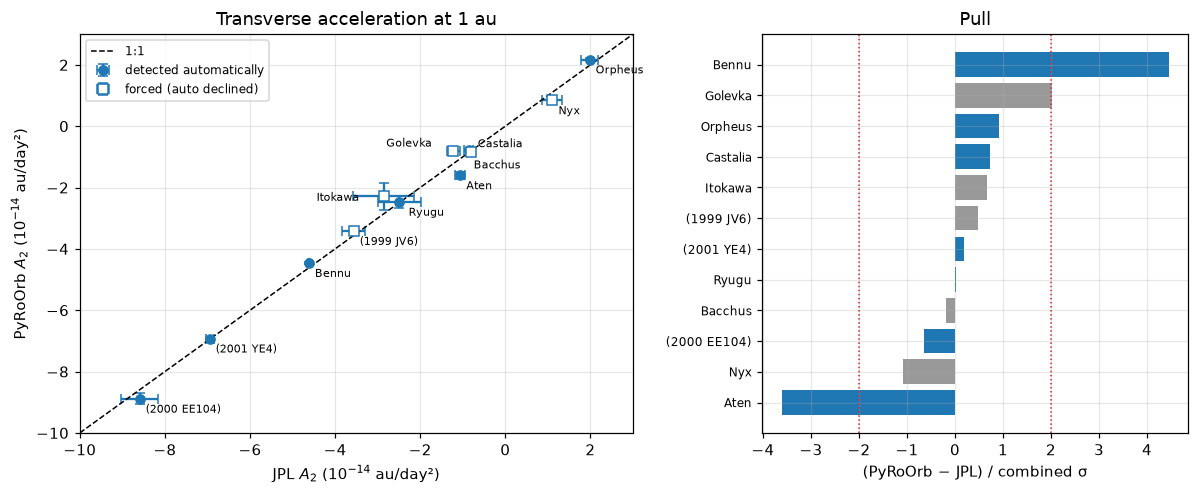

median |pull| 0.7;  within 2 sigma: 9 of 12
median sigma ratio PyRoOrb/JPL: 0.40


In [10]:
fig, (ax, axp) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
u = 1e-14
for fired, mk, lab in ((True, "o", "detected automatically"), (False, "s", "forced (auto declined)")):
    d = det[det.fired == fired]
    ax.errorbar(d.jpl_A2 / u, d.A2 / u, xerr=d.jpl_sA2 / u, yerr=d.sA2 / u, fmt=mk, ms=6,
                capsize=3, mfc="C0" if fired else "white", color="C0", label=lab)
OFFSET = {"6489": (-44, 3), "2063": (2, -11), "4769": (6, 2), "25143": (-44, -3), "162173": (6, -9)}
for des, r in det.iterrows():
    ax.annotate(short(des), (r.jpl_A2 / u, r.A2 / u), fontsize=7,
                xytext=OFFSET.get(des, (4, -9)), textcoords="offset points")
lim = [-10, 3]
ax.plot(lim, lim, "k--", lw=1, label="1:1")
ax.set(xlim=lim, ylim=lim, xlabel=r"JPL $A_2$ ($10^{-14}$ au/day²)",
       ylabel=r"PyRoOrb $A_2$ ($10^{-14}$ au/day²)", title="Transverse acceleration at 1 au")
ax.legend(fontsize=8, loc="upper left")

order = det.sort_values("pull")
axp.barh(range(len(order)), order.pull, color=["C0" if f else "0.6" for f in order.fired])
axp.set_yticks(range(len(order)), [short(d) for d in order.index], fontsize=8)
for x in (-2, 2):
    axp.axvline(x, color="C3", ls=":", lw=1)
axp.set(xlabel="(PyRoOrb − JPL) / combined σ", title="Pull")
plt.tight_layout(); plt.show()
print(f"median |pull| {det.pull.abs().median():.1f};  within 2 sigma: {(det.pull.abs() < 2).sum()} of {len(det)}")
print(f"median sigma ratio PyRoOrb/JPL: {(det.sA2 / det.jpl_sA2).median():.2f}")

Nine of the twelve agree with JPL within 2σ, and the median |pull| is 0.7. The forced fits of
the automatic misses (grey bars, open squares) agree as well as the automatic detections do.
The values span a factor of ten, from Castalia's $-0.8\times10^{-14}$ to 2000 EE104's
$-8.9\times10^{-14}$, and both signs: Nyx and Orpheus drift outward, so they rotate prograde.

Three need a word.

* **Bennu, +4.5σ (ratio 0.97).** The reference is the pre-arrival solution of Chesley et al.
  (2014), with its own data set, weights and force model. Both uncertainties are 0.5% of the
  value, so a 3% difference is many sigma; it is the size of the differences one expects
  between two careful but different solutions. (JPL itself no longer quotes an $A_2$ for Bennu.)
* **Golevka, +2.0σ.** A forced fit; see §3.
* **(2062) Aten, −3.6σ (ratio 1.5).** PyRoOrb finds a 50% larger drift than JPL. The cell below
  looks at where it comes from.

PyRoOrb's formal uncertainties are smaller than JPL's (median ratio 0.40), so the pulls are
dominated by JPL's σ. Measured against PyRoOrb's own σ alone, Castalia, Nyx, Orpheus and Golevka
would look like 2-3.4σ disagreements as well. JPL's weights for older and lower-quality
astrometry are generally more conservative, and its σ are the more realistic of the two.

### Aten: the same data, a different drift

JPL's Aten solution used observations up to November 2019, and the MPC has none newer, so the
two fits see the same 64-year arc. Fitting the forced model to parts of it shows what the drift
rests on:

In [11]:
obs = pyroorb.fetch_observations("2062")
for label, start in (("1976 on (drops the 3 precovery positions of 1955)", "1976-01-01"),
                     ("1995 on (CCD era only)", "1995-01-01")):
    sub = obs.select(start=start)
    f = pyroorb.fit_orbit(sub, designation="2062", nongrav="yarkovsky")
    a2, s2 = f.nongrav_params["A2"], f.as_dict()["nongrav_sigmas"]["A2"]
    print(f"{label:52s} {len(sub):5d} obs   A2 = {a2:+.2e} +/- {s2:.1e}")
print(f"{'all, automatic fit':52s} {len(obs):5d} obs   A2 = {sample.loc['2062', 'A2']:+.2e} +/- {sample.loc['2062', 'sA2']:.1e}")
print(f"{'JPL':52s} {sample.loc['2062', 'jpl_nobs']:5d} obs   A2 = {sample.loc['2062', 'jpl_A2']:+.2e} +/- {sample.loc['2062', 'jpl_sA2']:.1e}")

1976 on (drops the 3 precovery positions of 1955)     1051 obs   A2 = -1.64e-14 +/- 9.7e-16


1995 on (CCD era only)                                 925 obs   A2 = -2.77e-14 +/- 2.4e-15
all, automatic fit                                    1054 obs   A2 = -1.61e-14 +/- 9.9e-16
JPL                                                   1024 obs   A2 = -1.06e-14 +/- 1.1e-15


The three 1955 precovery positions make no difference. The CCD-era data alone (since 1995) want
an even larger drift; the 1976-1994 photographic positions are what pull it down toward JPL's
value. So the answer depends on how much weight those older positions get, and that is where
the two solutions most plausibly part. JPL weights each observation individually, by
station, catalogue and epoch, which PyRoOrb's weights only approximate. We cannot say from
here which value is right; a 50% disagreement on a 10σ detection is a reminder that $A_2$'s
formal σ does not include this kind of modelling choice.

## 5. From $A_2$ to a drift rate

Gauss's equation for the semi-major axis under a transverse acceleration $T$ is
$\dot a = 2\,T\,p\,/\,(n\sqrt{1-e^2}\;r)$, with $p = a(1-e^2)$. With $T = A_2\,(r_0/r)^2$,
$r_0 = 1$ au, and the average over one orbit (in mean anomaly, $dM = r^2 df / (a^2\sqrt{1-e^2})$,
and $\langle 1/r \rangle_f = 1/p$) the result is

$$\left\langle \frac{da}{dt} \right\rangle = \frac{2 A_2}{n\,(1-e^2)} \left(\frac{r_0}{a}\right)^2 ,$$

the expression Farnocchia et al. (2013) use to convert between the two. We check it below by
averaging the instantaneous rate $\dot a = 2a^2\,(\mathbf v\cdot\mathbf T)/\mu$ along Bennu's
real, planet-perturbed trajectory over 20 years.

In [12]:
from astropy.time import Time
GK = 0.01720209895                          # Gaussian gravitational constant, rad/day
AU_PER_MYR = 365.25e6                       # (au/day) -> (au/Myr)

def dadt(A2, a, e):
    """Orbit-averaged da/dt (au/Myr) of a transverse A2 (1 au / r)^2 acceleration."""
    n = GK / a**1.5
    return 2 * A2 / (n * (1 - e**2) * a**2) * AU_PER_MYR

# numerical check on Bennu: average 2 a^2 (v . T) / mu along the propagated orbit
fb = fits["101955"]
A2b = fb.nongrav_params["A2"]
t = Time(fb.epoch_jd() + np.linspace(-10, 10, 4001) * 365.25, format="jd", scale="tdb")
st = pyroorb.propagate(fb, t)
r, v = st[:, :3], st[:, 3:]
rn = np.linalg.norm(r, axis=1)
h = np.cross(r, v)
that = np.cross(h / np.linalg.norm(h, axis=1)[:, None], r / rn[:, None])   # transverse unit vector
a_osc = 1 / (2 / rn - np.einsum("ij,ij->i", v, v) / GK**2)
rate = 2 * a_osc**2 * np.einsum("ij,ij->i", v, that) * A2b / rn**2 / GK**2
el = fb.elements()
print(f"Bennu, PyRoOrb A2 = {A2b:.4e} au/day^2")
print(f"  analytic formula:            da/dt = {dadt(A2b, el['a'], el['e']) * 1e4:7.2f} e-4 au/Myr")
print(f"  averaged along the orbit:    da/dt = {rate.mean() * AU_PER_MYR * 1e4:7.2f} e-4 au/Myr")
print(f"  Chesley et al. 2014:         da/dt =  -19.00 +/- 0.10 e-4 au/Myr  (their A2 = -4.618e-14)")
print(f"  the formula with their A2:   da/dt = {dadt(BENNU_A2_CHESLEY14[0], el['a'], el['e']) * 1e4:7.2f} e-4 au/Myr")

Bennu, PyRoOrb A2 = -4.4662e-14 au/day^2
  analytic formula:            da/dt =  -18.65 e-4 au/Myr
  averaged along the orbit:    da/dt =  -18.72 e-4 au/Myr
  Chesley et al. 2014:         da/dt =  -19.00 +/- 0.10 e-4 au/Myr  (their A2 = -4.618e-14)
  the formula with their A2:   da/dt =  -19.28 e-4 au/Myr


The formula and the average along the real, planet-perturbed orbit agree to 0.4% (the rest is
how $a$ and $e$ wander along the actual trajectory). Bennu's semi-major axis shrinks by
$1.87\times10^{-3}$ au per million years, **about 280 metres per year**. Applied to Chesley et al.'s
$A_2$ the formula gives 1.5% more than the −19.0 they quote. That is the level at which the
choice of the $a$ and $e$ used in the conversion, and of the averaging, matters; it is far below
the spread between objects that the next plot is about.

## 6. Drift against size

The Yarkovsky acceleration is a surface force on a volume of mass, $\propto D^2/(\rho D^3) = 1/(\rho D)$,
times the cosine of the spin axis' obliquity and a thermal efficiency that depends on the
surface's thermal inertia and the spin rate. At fixed density, obliquity and thermal properties,
$|da/dt| \propto 1/D$. Real asteroids scatter around that line by their unknown obliquities
(a pole near the orbit plane gives almost no drift) and densities.

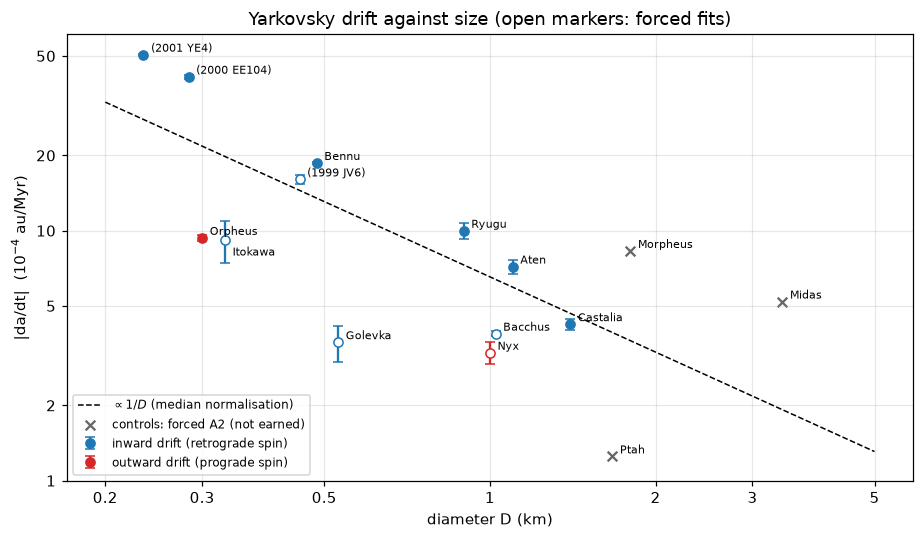

free power-law fit over the 12 detections: |da/dt| ~ D^-1.12
1 au/Myr = 149598 m/yr, so the 1/D line reads 98 m/yr at D = 1 km


In [13]:
sample["dadt"] = [dadt(r.A2, r.a, r.e) for _, r in sample.iterrows()]
sample["s_dadt"] = abs(sample.dadt * sample.sA2 / sample.A2)
sample["jpl_dadt"] = [dadt(r.jpl_A2, r.a, r.e) for _, r in sample.iterrows()]
det = sample[~sample.control]

fig, ax = plt.subplots(figsize=(8.5, 5))
D = np.logspace(np.log10(0.2), np.log10(5), 50)
k = np.exp(np.median(np.log(det.dadt.abs() * det.D_km)))       # 1/D line through the sample's median
ax.plot(D, k / D * 1e4, "k--", lw=1, label=r"$\propto 1/D$ (median normalisation)")
for sign, c, lab in ((-1, "C0", "inward drift (retrograde spin)"), (1, "C3", "outward drift (prograde spin)")):
    for fired in (True, False):
        d = det[(np.sign(det.dadt) == sign) & (det.fired == fired)]
        ax.errorbar(d.D_km, d.dadt.abs() * 1e4, yerr=d.s_dadt * 1e4, fmt="o", color=c, capsize=3,
                    mfc=c if fired else "white", label=lab if fired else None)
c = sample[sample.control]
ax.scatter(c.D_km, c.dadt.abs() * 1e4, marker="x", color="0.4", s=40,
           label="controls: forced A2 (not earned)")
for des, r in sample.iterrows():
    ax.annotate(short(des), (r.D_km, abs(r.dadt) * 1e4), fontsize=7,
                xytext=(5, -10) if des == "25143" else (5, 2), textcoords="offset points")
ax.set(xscale="log", yscale="log", xlabel="diameter D (km)", ylabel=r"|da/dt|  ($10^{-4}$ au/Myr)",
       title="Yarkovsky drift against size (open markers: forced fits)")
ax.set_xticks([0.2, 0.3, 0.5, 1, 2, 3, 5], ["0.2", "0.3", "0.5", "1", "2", "3", "5"])
ax.set_yticks([1, 2, 5, 10, 20, 50], ["1", "2", "5", "10", "20", "50"])
ax.minorticks_off()
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

slope, icpt = np.polyfit(np.log10(det.D_km), np.log10(det.dadt.abs()), 1)
print(f"free power-law fit over the {len(det)} detections: |da/dt| ~ D^{slope:.2f}")
print(f"1 au/Myr = {1.495978707e11 / 1e6:.0f} m/yr, so the 1/D line reads {k * 1.495978707e5:.0f} m/yr at D = 1 km")

The twelve detections follow the $1/D$ law: a free power-law fit gives an exponent of
**−1.1**, against −1 expected. Around the line they scatter by a factor of about three, as they
should: the line assumes the same density, obliquity and thermal properties for all, and
these real objects differ in all three. The smallest, 2000 EE104 and 2001 YE4 (about 250 m, sizes
from $H$ with an assumed albedo), drift fastest, 0.004-0.005 au per million years, or 600-750 m/yr.
At 1 km the line reads about 100 m/yr.

The controls' forced values (grey crosses) sit where real drifts should not be. Midas, at 3.4 km,
would need to drift almost three times faster than the line allows for its size, and Morpheus
(1.8 km) more than twice as fast. Combined with the unchanged rms, that says these $A_2$ values are fitting
noise. The automatic fit's refusal was right.

## 7. Weighing two asteroids with Bennu's drift

Two of the sample were visited by spacecraft that measured their mass and volume directly:
(162173) Ryugu by Hayabusa2 and (25143) Itokawa by Hayabusa. Bennu, visited by OSIRIS-REx, can
serve as the yardstick. If two bodies share the same thermal behaviour, their $A_2$ ratio is

$$\frac{A_2}{A_{2,\mathrm B}} = \frac{D_\mathrm B}{D}\;\frac{\rho_\mathrm B}{\rho}\;\frac{\cos\gamma}{\cos\gamma_\mathrm B},$$

so a measured $A_2$, size and obliquity $\gamma$ give the density. This is the scaling Farnocchia
et al. (2013) used to judge whether a detected drift is physically plausible. The spacecraft values:

| | volume-equivalent D | obliquity γ | bulk density | thermal inertia | rotation |
|---|---|---|---|---|---|
| Bennu | 0.490 km | 177.6° | 1190 ± 13 kg/m³ | ~350 | 4.3 h |
| Ryugu | 0.896 km | 171.6° | 1190 ± 20 kg/m³ | ~225-300 | 7.6 h |
| Itokawa | 0.328 km | ~178° | 1900 ± 130 kg/m³ | ~750 | 12.1 h |

Sources: Bennu, Lauretta et al. 2019 (*Nature* 568, 55) and DellaGiustina et al. 2019
(*Nat. Astron.* 3, 341); Ryugu, Watanabe et al. 2019 (*Science* 364, 268; volume 0.377 km³)
and Okada et al. 2020 (*Nature* 579, 518); Itokawa, Fujiwara et al. 2006 (*Science* 312, 1330;
volume 0.0184 km³), Demura et al. 2006 (*Science* 312, 1347; pole) and Müller et al. 2005
(*A&A* 443, 347). Thermal inertia in J m⁻² K⁻¹ s⁻½.

In [14]:
BENNU = dict(D=0.490, gamma=177.6, rho=1190.0)
TARGETS = {"162173": dict(D=0.896, gamma=171.6, rho=1190.0, s_rho=20.0),
           "25143":  dict(D=0.328, gamma=178.0, rho=1900.0, s_rho=130.0)}
A2B, sA2B = sample.loc["101955", ["A2", "sA2"]]
cosB = np.cos(np.radians(BENNU["gamma"]))
for des, p in TARGETS.items():
    for label, (A2, sA2) in (("PyRoOrb", sample.loc[des, ["A2", "sA2"]]),
                             ("JPL", sample.loc[des, ["jpl_A2", "jpl_sA2"]])):
        rho = BENNU["rho"] * (A2B / A2) * (BENNU["D"] / p["D"]) * (np.cos(np.radians(p["gamma"])) / cosB)
        s_rho = rho * np.hypot(sA2 / A2, sA2B / A2B)
        print(f"{sample.loc[des, 'name']:22s} from {label:7s} A2 = {A2:.3e}: rho = {rho:5.0f} +/- {s_rho:4.0f} kg/m^3"
              f"   (spacecraft: {p['rho']:.0f} +/- {p['s_rho']:.0f};  ratio {rho / p['rho']:.2f})")

162173 Ryugu (1999 JU3) from PyRoOrb A2 = -2.472e-14: rho =  1164 +/-   87 kg/m^3   (spacecraft: 1190 +/- 20;  ratio 0.98)
162173 Ryugu (1999 JU3) from JPL     A2 = -2.487e-14: rho =  1157 +/-  233 kg/m^3   (spacecraft: 1190 +/- 20;  ratio 0.97)
25143 Itokawa (1998 SF36) from PyRoOrb A2 = -2.285e-14: rho =  3476 +/-  667 kg/m^3   (spacecraft: 1900 +/- 130;  ratio 1.83)
25143 Itokawa (1998 SF36) from JPL     A2 = -2.855e-14: rho =  2782 +/-  701 kg/m^3   (spacecraft: 1900 +/- 130;  ratio 1.46)


**Ryugu comes out at 1164 ± 87 kg/m³, against 1190 ± 20 from Hayabusa2: 2% low, 0.3σ.** With
JPL's $A_2$ the answer is the same with an uncertainty 2.7 times larger. This works because Ryugu
is Bennu's near twin: both are dark carbonaceous rubble piles with similar thermal inertia,
similar spin periods and nearly the same retrograde obliquity, so the thermal efficiency the
scaling assumes equal really is nearly equal. Weighing an asteroid by its drift is the method
Chesley et al. (2014) used for Bennu before OSIRIS-REx arrived (they predicted
1260 ± 70 kg/m³); here it runs in reverse, with Bennu as the calibrator.

**Itokawa comes out 1.5-1.8 times too dense** (3480 ± 670 from PyRoOrb's forced $A_2$, 2780 ± 700
from JPL's, against 1900 ± 130 measured). Itokawa is not Bennu's twin. It is a bright S-type
with roughly twice Bennu's thermal inertia, a 12-hour spin, an elongated shape and a much
higher albedo (it absorbs less sunlight), and each of these changes how efficiently sunlight
becomes thrust. The scaling assumes they are all equal, so it overestimates the density. Its
$A_2$ is also only a 4-5σ detection. The method works between analogues and fails across
types unless a real thermal model replaces the scaling, which is what JPL now does for Bennu
itself.

## Takeaways

* **Agreement.** On twelve near-Earth asteroids with a published Yarkovsky drift, PyRoOrb's
  $A_2$ matches JPL's (or, for Bennu, Chesley et al. 2014's) within 2σ for nine, with a median
  pull of 0.7σ, over a factor of ten in $A_2$ and both directions of drift. The exceptions are
  Bennu (3%, many σ only because both solutions are so precise), Golevka (2.0σ) and Aten (50%,
  3.6σ, on the same data; the answer depends on how the 1976-1994 photographic positions are
  weighted).
* **Automatic detection is conservative.** None of three controls fired, and the
  forced fits show why that matters: an $A_2$ forced on them reaches a formal 5-6σ while
  explaining nothing and implying impossibly fast drifts. Seven of twelve real drifts were found
  unaided.
* **Its blind spot is radar.** All five misses are radar objects. The decision is made on the
  optical positions before the radar joins, so a drift that only the radar can separate from
  the orbit is never tested against the radar. A gravity-only fit whose optical rms *worsens*
  when the radar joins is the tell; then fit `nongrav="yarkovsky"` and compare. For Bacchus and
  1999 JV6 the forced $A_2$ agrees with JPL to 0.2σ and 0.5σ.
* **Physics.** Converted to $da/dt$, the drifts follow the expected $1/D$ law (fitted exponent
  −1.1) with the factor-of-three scatter that obliquity and composition give. Bennu loses
  about 280 m of semi-major axis per year.
* **Weighing asteroids.** Scaled from Bennu, Ryugu's drift gives its density to 2% (0.3σ) of the
  Hayabusa2 value. Itokawa's gives a value 1.5-1.8 times too high, because the scaling assumes
  Bennu's thermal behaviour and Itokawa is a different kind of body.

**Caveats.** Twelve detections and three controls are a demonstration, not a survey; the sample
leaves out the slowest fits (Icarus, Hathor, 1992 BF) and the largest data sets (Apophis,
Phaethon). PyRoOrb fits $A_2$ alone where JPL sometimes adds a radial $A_1$, and uses the MPC's
observations and its own weights and outlier rejection, not JPL's. Uncertainties here are
formal, and PyRoOrb's are typically 2.5 times smaller than JPL's. The two smallest diameters
come from $H$ with an assumed albedo of 0.14 and could be off by a factor of 1.5. Re-running
later uses newer observations, so the numbers can shift a little. Runtime on the machine that
last ran it: about 14 minutes.